# PBL-2: Intelligent AgTech — Clustering and Hidden Markov Models

## 1. Problem Identification

### Problem Statement
The objective of this project is to apply unsupervised machine learning techniques to agricultural data to identify patterns among soil and environmental conditions. Different clustering algorithms will be implemented and compared. A Hidden Markov Model (HMM) will also be explored to model relationships between hidden states and observed agricultural conditions.

### Objectives
1. Understand and preprocess the agricultural dataset.
2. Apply different clustering algorithms to identify groups in the data.
3. Implement a Hidden Markov Model using clearly defined states and observations.
4. Compare model performance using appropriate evaluation methods.
5. Interpret the results and identify the limitations of the analysis.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

from hmmlearn import hmm

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
from pathlib import Path

data_path = Path("..") / "Data-processed" / "crop_recommendation.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset shape: (2200, 8)
Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [10]:
print("Dataset Information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumber of unique crops:", df["label"].nunique())

print("\nSamples per crop:")
print(df["label"].value_counts().sort_index())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB

Missing values in each column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0

Number of unique crops: 22

Samples per crop:
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100

In [11]:
df.describe().round(2)

,N,P,K,temperature,humidity,ph,rainfall
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


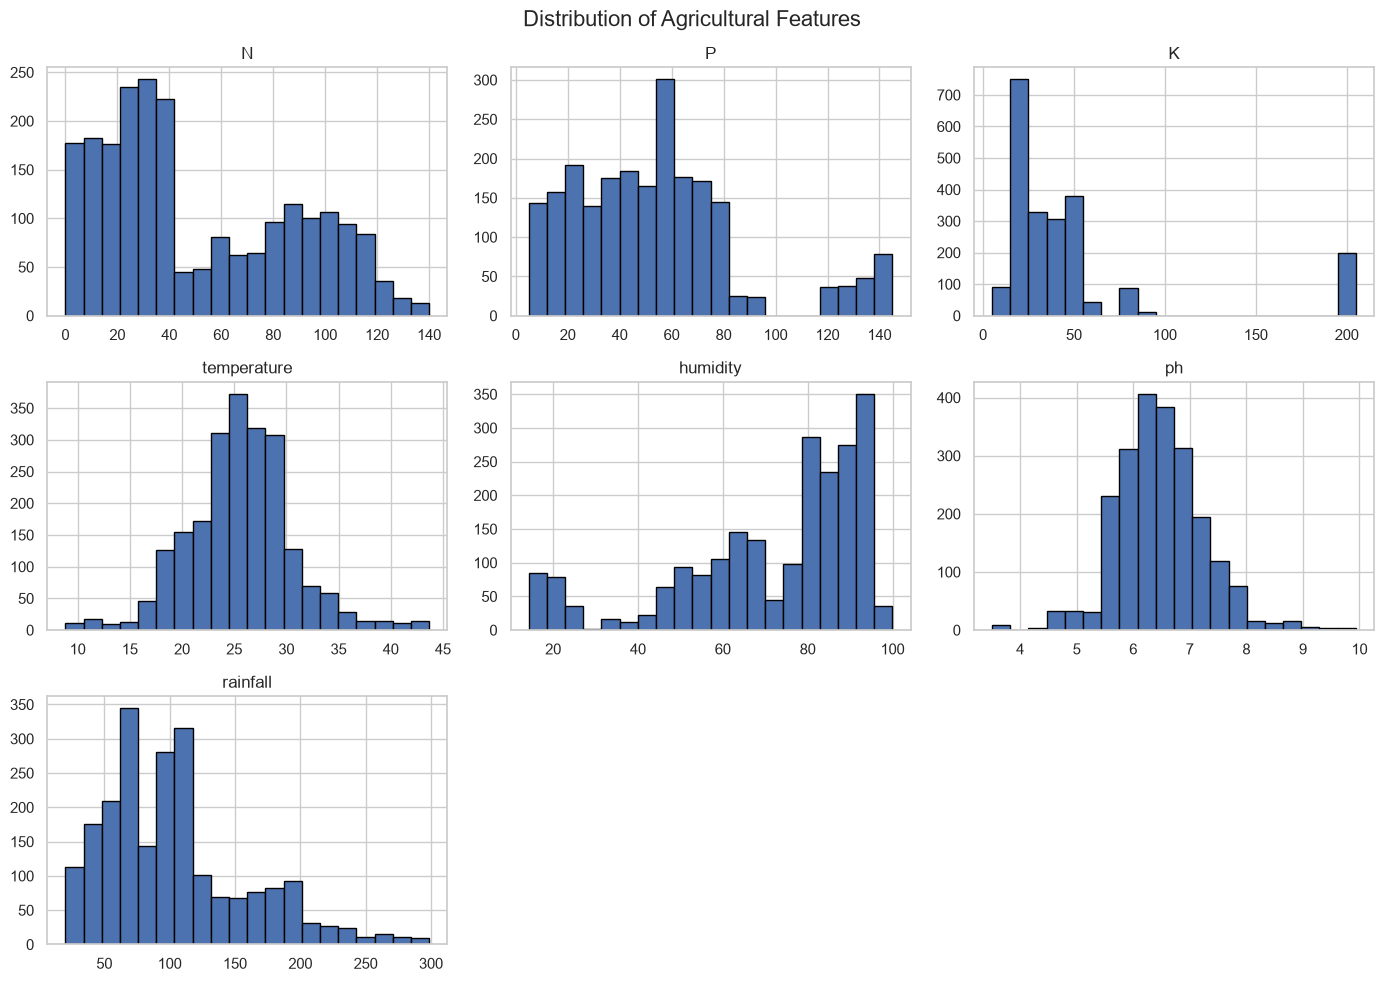

In [12]:
numerical_features = [
    "N", "P", "K",
    "temperature", "humidity", "ph", "rainfall"
]

df[numerical_features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Agricultural Features", fontsize=16)
plt.tight_layout()
plt.show()

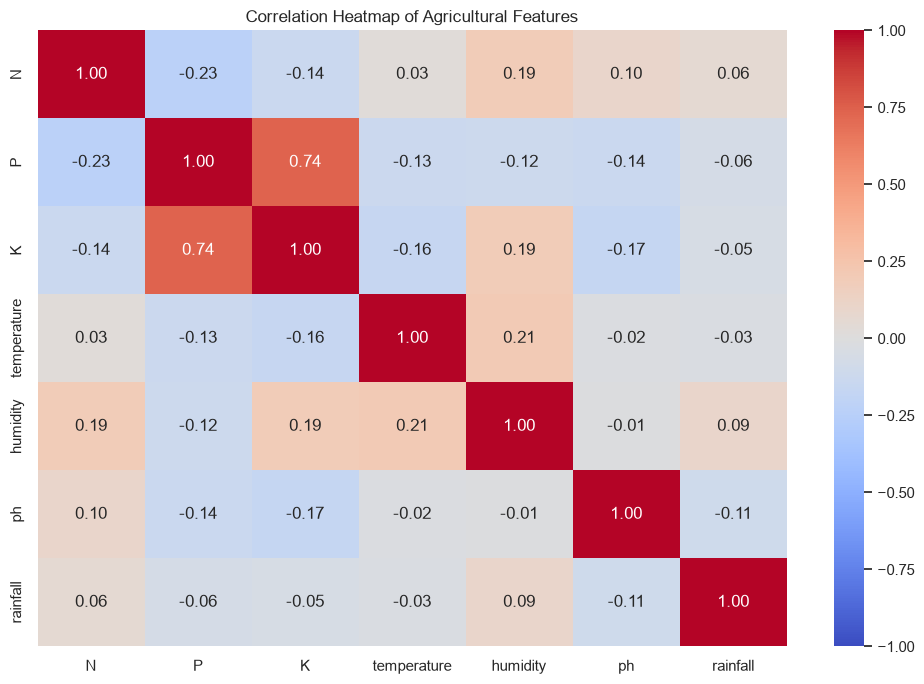

In [13]:
correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Agricultural Features")
plt.tight_layout()
plt.show()

In [16]:
# Select numerical features for clustering
X = df[numerical_features].copy()

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)

print("\nScaled feature means:")
print(np.round(X_scaled.mean(axis=0), 2))

print("\nScaled feature standard deviations:")
print(np.round(X_scaled.std(axis=0), 2))

Original data shape: (2200, 7)
Scaled data shape: (2200, 7)

Scaled feature means:
[-0.  0. -0.  0. -0. -0.  0.]

Scaled feature standard deviations:
[1. 1. 1. 1. 1. 1. 1.]


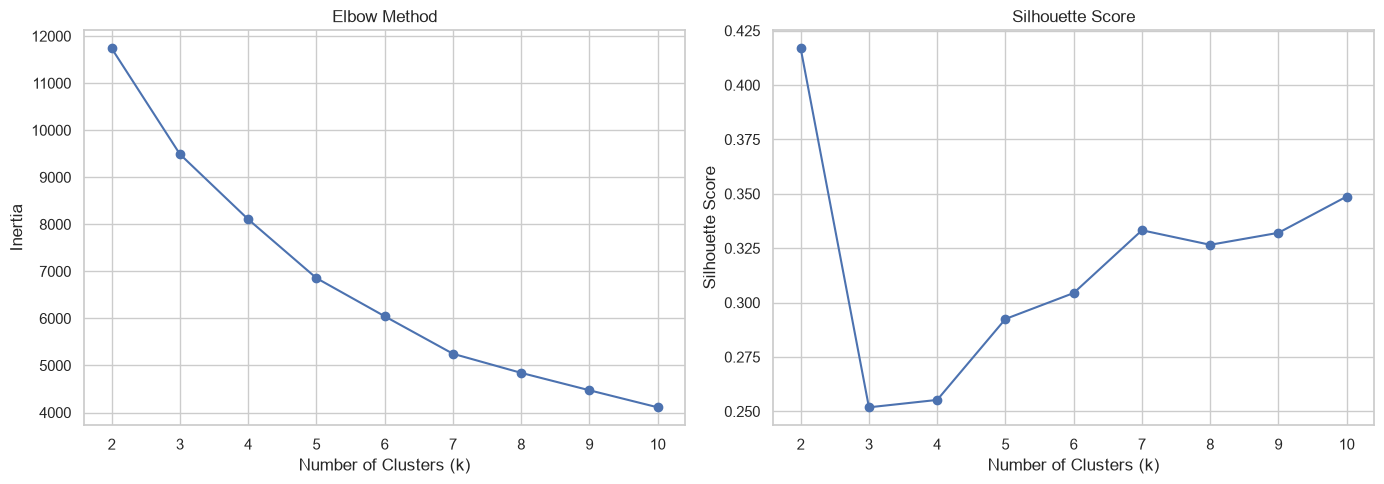

Best k according to silhouette score: 2


In [18]:
inertia_values = []
silhouette_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, cluster_labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_values, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

best_k_silhouette = list(k_values)[np.argmax(silhouette_values)]
print("Best k according to silhouette score:", best_k_silhouette)

In [25]:
from sklearn.metrics import normalized_mutual_info_score

print("Inertia at selected k:", round(kmeans_model.inertia_, 4))

nmi = normalized_mutual_info_score(
    df["label"],
    df["KMeans_Cluster"]
)

print("Normalized Mutual Information:", round(nmi, 4))

Inertia at selected k: 11738.0113
Normalized Mutual Information: 0.1794


In [22]:
# ============================================
# K-MEANS CLUSTERING
# ============================================

# Step 1: Initialize the K-Means model
kmeans_model = KMeans(
    n_clusters=best_k_silhouette,
    random_state=42,
    n_init=10
)

# Step 2: Fit the model and assign cluster labels
df["KMeans_Cluster"] = kmeans_model.fit_predict(X_scaled)

# Step 3: Display the number of clusters
print("K-MEANS CLUSTERING RESULTS")
print("=" * 50)
print("Optimal number of clusters:", best_k_silhouette)

# Step 4: Display the number of samples in each cluster
cluster_counts = (
    df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Number of Samples")
)

print("\nSamples in Each Cluster:")
display(cluster_counts)

# Step 5: Display cluster centers in a formatted table
cluster_centers_df = pd.DataFrame(
    kmeans_model.cluster_centers_,
    columns=numerical_features
)

cluster_centers_df.index.name = "Cluster"
cluster_centers_df = cluster_centers_df.round(2)

print("Cluster Centers (Standardized Scale):")
display(cluster_centers_df)

# Step 6: Evaluate the clustering model
silhouette = silhouette_score(X_scaled, df["KMeans_Cluster"])
davies_bouldin = davies_bouldin_score(X_scaled, df["KMeans_Cluster"])
calinski_harabasz = calinski_harabasz_score(X_scaled, df["KMeans_Cluster"])
ari = adjusted_rand_score(df["label"], df["KMeans_Cluster"])

# Step 7: Display evaluation metrics as a formatted table
kmeans_metrics = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index",
        "Adjusted Rand Index"
    ],
    "Score": [
        silhouette,
        davies_bouldin,
        calinski_harabasz,
        ari
    ],
    "Interpretation": [
        "Higher is better",
        "Lower is better",
        "Higher is better",
        "Higher is better"
    ]
})

kmeans_metrics["Score"] = kmeans_metrics["Score"].round(4)

print("\nClustering Evaluation Metrics:")
display(kmeans_metrics)

K-MEANS CLUSTERING RESULTS
Optimal number of clusters: 2

Samples in Each Cluster:


,Cluster,Number of Samples
0,0,2000
1,1,200


Cluster Centers (Standardized Scale):


,N,P,K,temperature,humidity,ph,rainfall
Cluster,,,,,,,
0,0.08,-0.24,-0.3,0.05,-0.07,0.06,0.02
1,-0.77,2.43,3.0,-0.47,0.70,-0.64,-0.22



Clustering Evaluation Metrics:


,Metric,Score,Interpretation
0,Silhouette Score,0.4168,Higher is better
1,Davies-Bouldin Index,0.7968,Lower is better
2,Calinski-Harabasz Index,685.7253,Higher is better
3,Adjusted Rand Index,0.0185,Higher is better


NameError: name 'res' is not defined

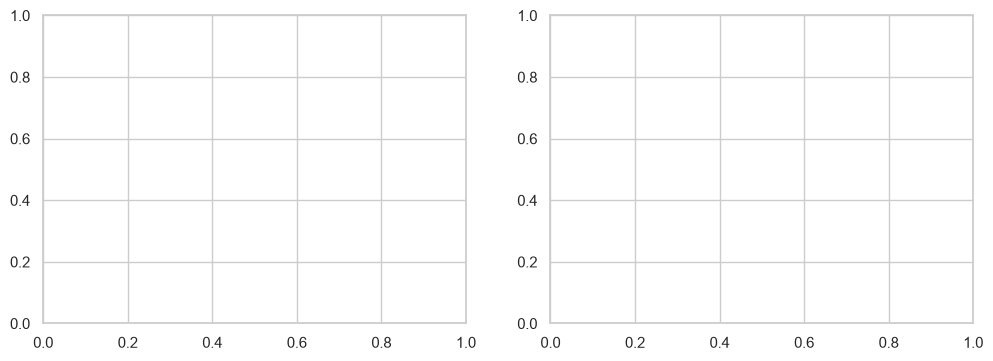

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ks = list(res.keys())
inertias = [res[k][0] for k in ks]
silhouettes = [res[k][1] for k in ks]

axes[0].plot(ks, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(ks, silhouettes, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

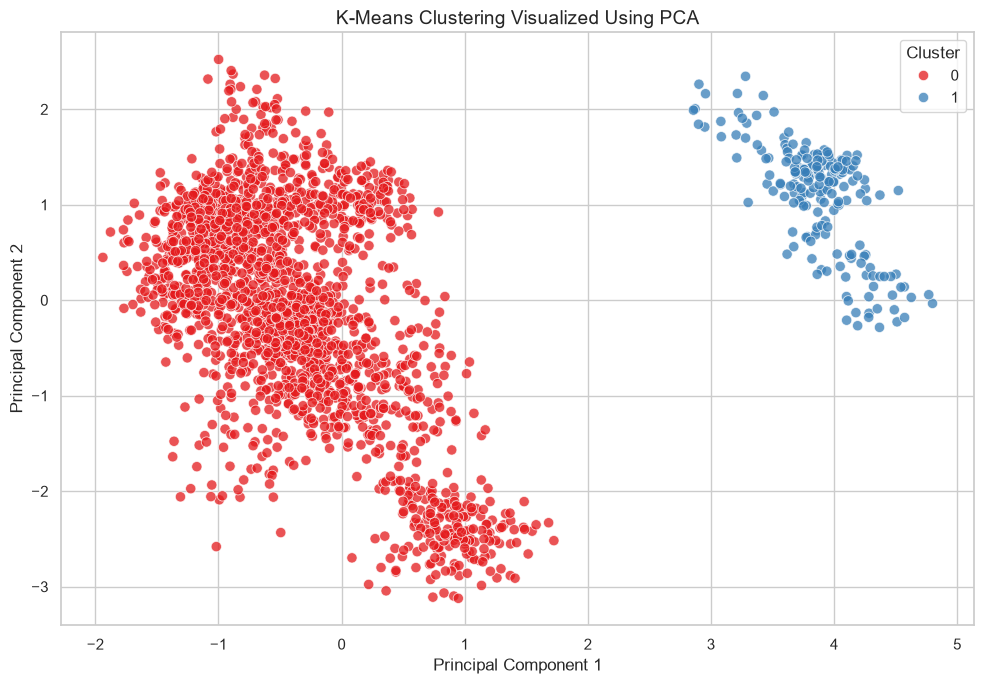

PCA Explained Variance:


,Principal Component,Explained Variance Ratio,Explained Variance (%)
0,PC1,0.2759,27.59
1,PC2,0.1848,18.48


Total variance retained by 2 components: 46.07 %


In [27]:
# ============================================
# K-MEANS CLUSTER VISUALIZATION USING PCA
# ============================================

# Step 1: Reduce the standardized features to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Step 2: Create a DataFrame for visualization
pca_df = pd.DataFrame({
    "Principal Component 1": X_pca[:, 0],
    "Principal Component 2": X_pca[:, 1],
    "KMeans_Cluster": df["KMeans_Cluster"]
})

# Step 3: Plot the clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="KMeans_Cluster",
    palette="Set1",
    s=55,
    alpha=0.75
)

plt.title("K-Means Clustering Visualized Using PCA", fontsize=14)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

# Step 4: Display explained variance
explained_variance = pca.explained_variance_ratio_

pca_variance_df = pd.DataFrame({
    "Principal Component": ["PC1", "PC2"],
    "Explained Variance Ratio": explained_variance,
    "Explained Variance (%)": explained_variance * 100
})

pca_variance_df["Explained Variance Ratio"] = (
    pca_variance_df["Explained Variance Ratio"].round(4)
)
pca_variance_df["Explained Variance (%)"] = (
    pca_variance_df["Explained Variance (%)"].round(2)
)

print("PCA Explained Variance:")
display(pca_variance_df)

print(
    "Total variance retained by 2 components:",
    round(explained_variance.sum() * 100, 2),
    "%"
)

In [41]:
from sklearn.metrics import normalized_mutual_info_score

print("Inertia:", round(kmeans_model.inertia_, 4))

nmi = normalized_mutual_info_score(
    df["label"],
    df["KMeans_Cluster"]
)

print("NMI:", round(nmi, 4))

Inertia: 11738.0113
NMI: 0.1794


In [42]:
print("Components retained for >=95% variance:", pca.n_components_)
print("Cumulative explained variance:", pca.explained_variance_ratio_.sum())

Components retained for >=95% variance: 2
Cumulative explained variance: 0.4607326252557196


In [43]:
print(pca.n_components)
print(pca.explained_variance_ratio_)
print(pca.explained_variance_ratio_.cumsum())

2
[0.27588831 0.18484431]
[0.27588831 0.46073263]


In [52]:
pca_95 = PCA(n_components=0.95)
Z_95 = pca_95.fit_transform(Xs)

print("Components for 95% variance:", pca_95.n_components_)
print("Cumulative variance:", pca_95.explained_variance_ratio_.sum())

Components for 95% variance: 6
Cumulative variance: 0.9724312590028592


In [51]:
from sklearn.preprocessing import StandardScaler

feats = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
Xs = StandardScaler().fit_transform(df[feats])

In [28]:
# ============================================
# AGGLOMERATIVE (HIERARCHICAL) CLUSTERING
# ============================================

# Step 1: Initialize the model
agg_model = AgglomerativeClustering(
    n_clusters=best_k_silhouette,
    linkage="ward"
)

# Step 2: Fit the model and assign cluster labels
df["Agglomerative_Cluster"] = agg_model.fit_predict(X_scaled)

# Step 3: Display the number of clusters
print("AGGLOMERATIVE CLUSTERING RESULTS")
print("=" * 50)
print("Number of clusters:", best_k_silhouette)

# Step 4: Display samples in each cluster
agg_cluster_counts = (
    df["Agglomerative_Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Number of Samples")
)

print("\nSamples in Each Cluster:")
display(agg_cluster_counts)

# Step 5: Evaluate the clustering model
agg_silhouette = silhouette_score(
    X_scaled, df["Agglomerative_Cluster"]
)

agg_davies_bouldin = davies_bouldin_score(
    X_scaled, df["Agglomerative_Cluster"]
)

agg_calinski_harabasz = calinski_harabasz_score(
    X_scaled, df["Agglomerative_Cluster"]
)

agg_ari = adjusted_rand_score(
    df["label"], df["Agglomerative_Cluster"]
)

# Step 6: Display metrics in a formatted table
agg_metrics = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index",
        "Adjusted Rand Index"
    ],
    "Score": [
        agg_silhouette,
        agg_davies_bouldin,
        agg_calinski_harabasz,
        agg_ari
    ],
    "Interpretation": [
        "Higher is better",
        "Lower is better",
        "Higher is better",
        "Higher is better"
    ]
})

agg_metrics["Score"] = agg_metrics["Score"].round(4)

print("\nClustering Evaluation Metrics:")
display(agg_metrics)

AGGLOMERATIVE CLUSTERING RESULTS
Number of clusters: 2

Samples in Each Cluster:


,Cluster,Number of Samples
0,0,2000
1,1,200



Clustering Evaluation Metrics:


,Metric,Score,Interpretation
0,Silhouette Score,0.4168,Higher is better
1,Davies-Bouldin Index,0.7968,Lower is better
2,Calinski-Harabasz Index,685.7253,Higher is better
3,Adjusted Rand Index,0.0185,Higher is better


In [40]:
%whos

Variable                   Type                       Data/Info
---------------------------------------------------------------
AgglomerativeClustering    type                       <class 'sklearn.cluster._<...>AgglomerativeClustering'>
DBSCAN                     type                       <class 'sklearn.cluster._dbscan.DBSCAN'>
KMeans                     ABCMeta                    <class 'sklearn.cluster._kmeans.KMeans'>
N                          int                        3
PCA                        ABCMeta                    <class 'sklearn.decomposition._pca.PCA'>
Path                       type                       <class 'pathlib.Path'>
StandardScaler             type                       <class 'sklearn.preproces<...>ng._data.StandardScaler'>
T                          int                        100
X                          DataFrame                  Shape: (2200, 7)
X_hmm                      ndarray                    2200x7: 15400 elems, type `float64`, 123200 bytes (

In [29]:
print([v for v in globals() if 'agg' in v.lower()])

['AgglomerativeClustering', 'agg_model', 'agg_cluster_counts', 'agg_silhouette', 'agg_davies_bouldin', 'agg_calinski_harabasz', 'agg_ari', 'agg_metrics']


In [30]:
# Get Agglomerative cluster labels
agg_labels = agg_model.fit_predict(X_scaled)

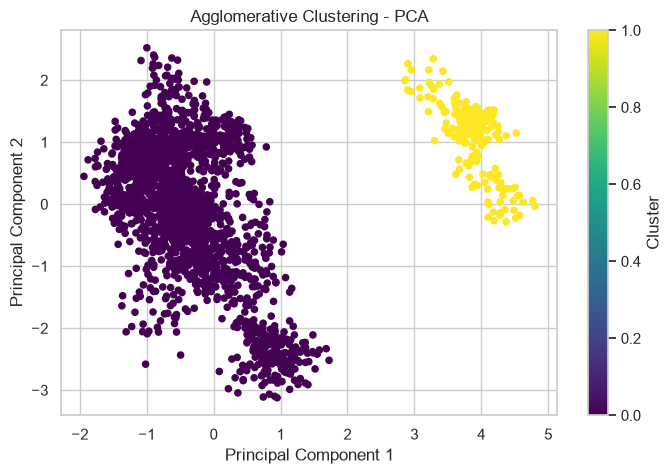

In [31]:
# PCA visualization for Agglomerative Clustering

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=agg_labels,
    cmap='viridis',
    s=20
)

plt.title("Agglomerative Clustering - PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

In [32]:
# ============================================
# DBSCAN CLUSTERING
# ============================================

# Step 1: Initialize and fit DBSCAN
dbscan_model = DBSCAN(
    eps=1.5,
    min_samples=10
)

df["DBSCAN_Cluster"] = dbscan_model.fit_predict(X_scaled)

# Step 2: Display cluster counts
print("DBSCAN CLUSTERING RESULTS")
print("=" * 50)

dbscan_counts = (
    df["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Number of Samples")
)

display(dbscan_counts)

# Step 3: Count clusters and noise points
dbscan_labels = df["DBSCAN_Cluster"].to_numpy()

n_noise = np.sum(dbscan_labels == -1)
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

print("Number of clusters (excluding noise):", n_clusters)
print("Number of noise points:", n_noise)
print("Percentage of noise points:", round(n_noise / len(df) * 100, 2), "%")

# Step 4: Evaluate DBSCAN, excluding noise points
# Noise points have label -1 and are excluded from these metrics.
non_noise_mask = dbscan_labels != -1
non_noise_X = X_scaled[non_noise_mask]
non_noise_labels = dbscan_labels[non_noise_mask]

if len(non_noise_labels) > 1 and len(np.unique(non_noise_labels)) >= 2:
    dbscan_silhouette = silhouette_score(
        non_noise_X, non_noise_labels
    )
    dbscan_davies_bouldin = davies_bouldin_score(
        non_noise_X, non_noise_labels
    )
    dbscan_calinski_harabasz = calinski_harabasz_score(
        non_noise_X, non_noise_labels
    )

    # ARI includes noise points as a separate predicted label (-1).
    dbscan_ari = adjusted_rand_score(
        df["label"], dbscan_labels
    )

    dbscan_metrics = pd.DataFrame({
        "Metric": [
            "Silhouette Score (excluding noise)",
            "Davies-Bouldin Index (excluding noise)",
            "Calinski-Harabasz Index (excluding noise)",
            "Adjusted Rand Index (including noise)"
        ],
        "Score": [
            dbscan_silhouette,
            dbscan_davies_bouldin,
            dbscan_calinski_harabasz,
            dbscan_ari
        ],
        "Interpretation": [
            "Higher is better",
            "Lower is better",
            "Higher is better",
            "Higher is better"
        ]
    })

    dbscan_metrics["Score"] = dbscan_metrics["Score"].round(4)

    print("\nDBSCAN Evaluation Metrics:")
    display(dbscan_metrics)

else:
    print(
        "\nInternal clustering metrics cannot be calculated reliably: "
        "DBSCAN must identify at least two non-noise clusters."
    )

DBSCAN CLUSTERING RESULTS


,Cluster,Number of Samples
0,0,2000
1,1,200


Number of clusters (excluding noise): 2
Number of noise points: 0
Percentage of noise points: 0.0 %

DBSCAN Evaluation Metrics:


,Metric,Score,Interpretation
0,Silhouette Score (excluding noise),0.4168,Higher is better
1,Davies-Bouldin Index (excluding noise),0.7968,Lower is better
2,Calinski-Harabasz Index (excluding noise),685.7253,Higher is better
3,Adjusted Rand Index (including noise),0.0185,Higher is better


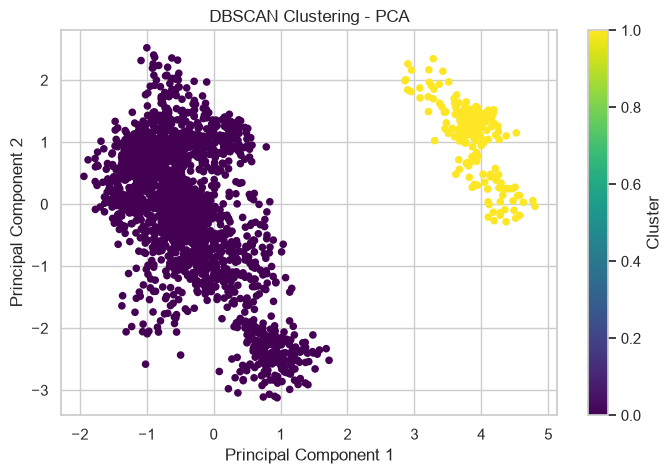

In [47]:
# PCA visualization for DBSCAN

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap='viridis',
    s=20
)

plt.title("DBSCAN Clustering - PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

In [33]:
# ============================================
# COMPARATIVE PERFORMANCE ANALYSIS
# ============================================

# Step 1: Calculate evaluation metrics for K-Means
kmeans_results = {
    "Algorithm": "K-Means",
    "Number of Clusters": df["KMeans_Cluster"].nunique(),
    "Silhouette Score": silhouette_score(
        X_scaled, df["KMeans_Cluster"]
    ),
    "Davies-Bouldin Index": davies_bouldin_score(
        X_scaled, df["KMeans_Cluster"]
    ),
    "Calinski-Harabasz Index": calinski_harabasz_score(
        X_scaled, df["KMeans_Cluster"]
    ),
    "Adjusted Rand Index": adjusted_rand_score(
        df["label"], df["KMeans_Cluster"]
    )
}

# Step 2: Calculate evaluation metrics for Agglomerative Clustering
agg_results = {
    "Algorithm": "Agglomerative",
    "Number of Clusters": df["Agglomerative_Cluster"].nunique(),
    "Silhouette Score": silhouette_score(
        X_scaled, df["Agglomerative_Cluster"]
    ),
    "Davies-Bouldin Index": davies_bouldin_score(
        X_scaled, df["Agglomerative_Cluster"]
    ),
    "Calinski-Harabasz Index": calinski_harabasz_score(
        X_scaled, df["Agglomerative_Cluster"]
    ),
    "Adjusted Rand Index": adjusted_rand_score(
        df["label"], df["Agglomerative_Cluster"]
    )
}

# Step 3: Calculate DBSCAN metrics when valid
dbscan_labels = df["DBSCAN_Cluster"].to_numpy()
non_noise_mask = dbscan_labels != -1
non_noise_labels = dbscan_labels[non_noise_mask]
non_noise_X = X_scaled[non_noise_mask]

dbscan_results = {
    "Algorithm": "DBSCAN",
    "Number of Clusters": len(set(dbscan_labels) - {-1}),
    "Silhouette Score": np.nan,
    "Davies-Bouldin Index": np.nan,
    "Calinski-Harabasz Index": np.nan,
    "Adjusted Rand Index": adjusted_rand_score(
        df["label"], dbscan_labels
    )
}

if (
    len(non_noise_labels) > 1
    and 2 <= len(np.unique(non_noise_labels)) < len(non_noise_labels)
):
    dbscan_results["Silhouette Score"] = silhouette_score(
        non_noise_X, non_noise_labels
    )
    dbscan_results["Davies-Bouldin Index"] = davies_bouldin_score(
        non_noise_X, non_noise_labels
    )
    dbscan_results["Calinski-Harabasz Index"] = calinski_harabasz_score(
        non_noise_X, non_noise_labels
    )

# Step 4: Combine all results into one table
comparison_df = pd.DataFrame([
    kmeans_results,
    agg_results,
    dbscan_results
])

numeric_columns = [
    "Silhouette Score",
    "Davies-Bouldin Index",
    "Calinski-Harabasz Index",
    "Adjusted Rand Index"
]

comparison_df[numeric_columns] = comparison_df[numeric_columns].round(4)

print("CLUSTERING ALGORITHM COMPARISON")
display(comparison_df)

print("\nHow to interpret the metrics:")
print("- Silhouette Score: Higher is generally better.")
print("- Davies-Bouldin Index: Lower is generally better.")
print("- Calinski-Harabasz Index: Higher is generally better.")
print("- Adjusted Rand Index: Higher indicates better agreement with crop labels.")
print("- NaN means the metric could not be calculated reliably.")

CLUSTERING ALGORITHM COMPARISON


,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Adjusted Rand Index
0,K-Means,2,0.4168,0.7968,685.7253,0.0185
1,Agglomerative,2,0.4168,0.7968,685.7253,0.0185
2,DBSCAN,2,0.4168,0.7968,685.7253,0.0185



How to interpret the metrics:
- Silhouette Score: Higher is generally better.
- Davies-Bouldin Index: Lower is generally better.
- Calinski-Harabasz Index: Higher is generally better.
- Adjusted Rand Index: Higher indicates better agreement with crop labels.
- NaN means the metric could not be calculated reliably.


## 3. Hidden Markov Model (HMM)

### 3.1 Introduction

A Hidden Markov Model (HMM) is a probabilistic model used to represent systems in which the underlying states are hidden, but observations generated by those states are visible.

An HMM consists of the following components:

1. **Hidden states:** The underlying states that cannot be observed directly.
2. **Observations:** The measurable data generated by the hidden states.
3. **Initial state probabilities:** The probabilities of starting in each hidden state.
4. **Transition probabilities:** The probabilities of moving from one hidden state to another.
5. **Emission probabilities:** The probabilities of observing particular data given a hidden state.

### 3.2 Objective

The objective of this experiment is to explore whether a Hidden Markov Model can identify latent environmental regimes from agricultural measurements.

The seven numerical features representing soil nutrients and environmental conditions will serve as observations. The model will attempt to learn hidden states and their transition probabilities.

### 3.3 Dataset Limitation

The agricultural dataset does not contain genuine temporal sequences. Therefore, the HMM implementation is exploratory, and the ordering of observations must not be interpreted as actual chronological agricultural development. The inferred states are latent statistical patterns, not verified crop growth stages or real seasonal transitions.

In [53]:
# ============================================
# HMM: PREPARE OBSERVATIONS
# ============================================

# Use standardized numerical features as observations
X_hmm = X_scaled.copy()

# Define the number of hidden states for the experiment
n_hidden_states = 3

# Divide the dataset into fixed-length artificial sequences.
# These are NOT genuine chronological sequences.
sequence_length = 100

n_samples = X_hmm.shape[0]

# Create sequence lengths, including any final shorter sequence
sequence_lengths = [
    sequence_length
] * (n_samples // sequence_length)

if n_samples % sequence_length != 0:
    sequence_lengths.append(n_samples % sequence_length)

print("HMM DATA PREPARATION")
print("=" * 45)
print("Number of observations:", n_samples)
print("Number of features:", X_hmm.shape[1])
print("Number of hidden states:", n_hidden_states)
print("Artificial sequence length:", sequence_length)
print("Number of sequences:", len(sequence_lengths))
print("Total observations across sequences:", sum(sequence_lengths))

print("\nObservation matrix shape:", X_hmm.shape)

print(
    "\nLimitation: these sequences are constructed from dataset row order "
    "and do not represent actual time."
)

HMM DATA PREPARATION
Number of observations: 2200
Number of features: 7
Number of hidden states: 3
Artificial sequence length: 100
Number of sequences: 22
Total observations across sequences: 2200

Observation matrix shape: (2200, 7)

Limitation: these sequences are constructed from dataset row order and do not represent actual time.


In [54]:
# ============================================
# HIDDEN MARKOV MODEL: TRAINING
# ============================================

# Step 1: Initialize the Gaussian HMM
hmm_model = hmm.GaussianHMM(
    n_components=n_hidden_states,
    covariance_type="diag",
    n_iter=200,
    random_state=42
)

# Step 2: Train the model
hmm_model.fit(X_hmm, lengths=sequence_lengths)

# Step 3: Predict the most likely hidden state for each observation
hidden_states = hmm_model.predict(X_hmm, lengths=sequence_lengths)

df["HMM_Hidden_State"] = hidden_states

print("HMM TRAINING RESULTS")
print("=" * 50)
print("Model converged:", hmm_model.monitor_.converged)
print("Number of iterations:", hmm_model.monitor_.iter)
print("Log-likelihood:", round(hmm_model.score(X_hmm, lengths=sequence_lengths), 4))

# Step 4: Display the number of observations assigned to each hidden state
state_counts = (
    pd.Series(hidden_states, name="Hidden State")
    .value_counts()
    .sort_index()
    .rename_axis("Hidden State")
    .reset_index(name="Number of Observations")
)

print("\nObservations in Each Hidden State:")
display(state_counts)

# Step 5: Display the initial state probabilities
initial_probabilities = pd.DataFrame({
    "Hidden State": range(n_hidden_states),
    "Initial Probability": hmm_model.startprob_
})

initial_probabilities["Initial Probability"] = (
    initial_probabilities["Initial Probability"].round(4)
)

print("\nInitial State Probabilities:")
display(initial_probabilities)

HMM TRAINING RESULTS
Model converged: True
Number of iterations: 29
Log-likelihood: -17251.5092

Observations in Each Hidden State:


,Hidden State,Number of Observations
0,0,1000
1,1,1000
2,2,200



Initial State Probabilities:


,Hidden State,Initial Probability
0,0,0.0361
1,1,0.8730
2,2,0.0909


HMM TRANSITION PROBABILITY MATRIX


Next State,State 0,State 1,State 2
Current State,,,
State 0,0.0014,0.9986,0.0
State 1,0.9867,0.0133,0.0
State 2,0.0000,0.0000,1.0


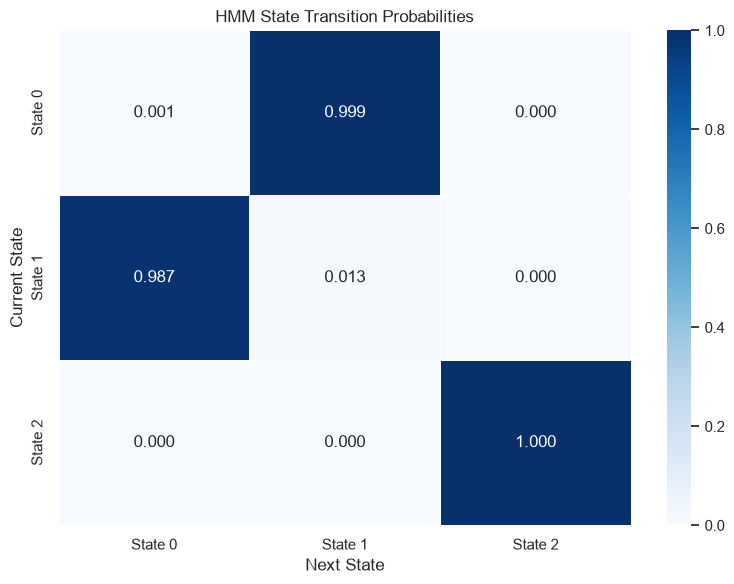


Transition Probability Validation:


,Hidden State,Sum of Transition Probabilities
0,State 0,1.0
1,State 1,1.0
2,State 2,1.0


In [55]:
# ============================================
# HMM: TRANSITION PROBABILITY MATRIX
# ============================================

# Step 1: Extract the transition probability matrix
transition_matrix = hmm_model.transmat_

# Step 2: Format it as a table
state_names = [
    f"State {i}" for i in range(n_hidden_states)
]

transition_df = pd.DataFrame(
    transition_matrix,
    index=state_names,
    columns=state_names
)

transition_df.index.name = "Current State"
transition_df.columns.name = "Next State"

print("HMM TRANSITION PROBABILITY MATRIX")
print("=" * 50)
display(transition_df.round(4))

# Step 3: Visualize the transition matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    transition_df,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title("HMM State Transition Probabilities")
plt.xlabel("Next State")
plt.ylabel("Current State")
plt.tight_layout()
plt.show()

# Step 4: Verify that each row sums to approximately 1
row_sums = transition_matrix.sum(axis=1)

transition_check_df = pd.DataFrame({
    "Hidden State": state_names,
    "Sum of Transition Probabilities": row_sums.round(6)
})

print("\nTransition Probability Validation:")
display(transition_check_df)

AVERAGE AGRICULTURAL CONDITIONS BY HIDDEN STATE


,N,P,K,temperature,humidity,ph,rainfall
Hidden State,,,,,,,
0,53.68,45.30,33.03,25.84,69.99,6.52,104.44
1,53.13,45.42,32.90,25.86,69.85,6.52,104.96
2,21.99,133.38,200.00,23.24,87.10,5.98,91.13



OBSERVATION COUNT BY HIDDEN STATE


,Hidden State,Number of Observations
0,0,1000
1,1,1000
2,2,200


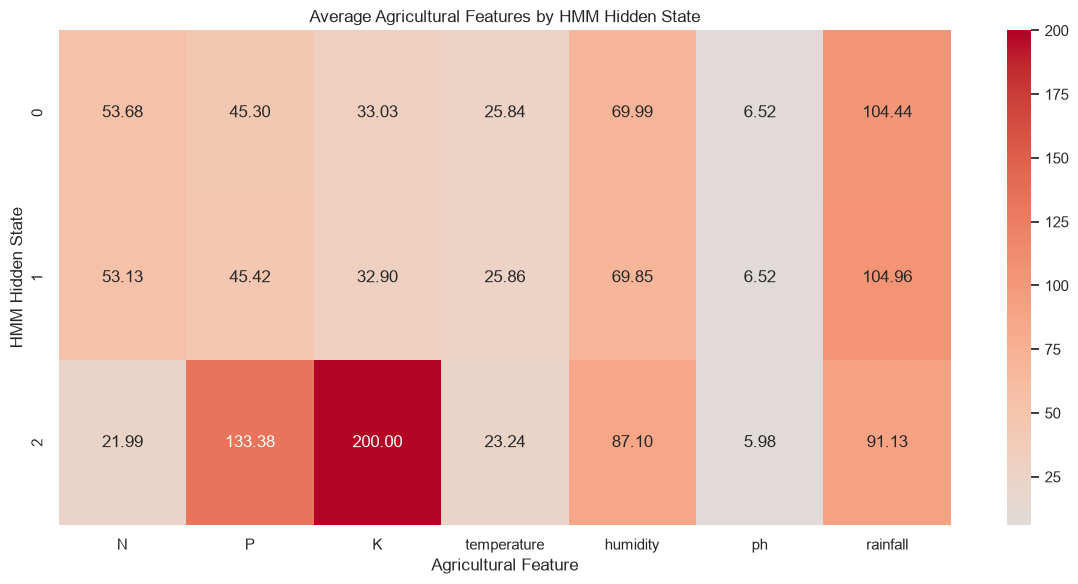

In [56]:
# ============================================
# HMM: HIDDEN STATE ANALYSIS
# ============================================

# Step 1: Calculate the average feature values for each hidden state
hmm_state_means = (
    df.groupby("HMM_Hidden_State")[numerical_features]
    .mean()
    .round(2)
)

hmm_state_means.index.name = "Hidden State"

print("AVERAGE AGRICULTURAL CONDITIONS BY HIDDEN STATE")
print("=" * 60)
display(hmm_state_means)

# Step 2: Count observations in each hidden state
hmm_state_counts = (
    df["HMM_Hidden_State"]
    .value_counts()
    .sort_index()
    .rename_axis("Hidden State")
    .reset_index(name="Number of Observations")
)

print("\nOBSERVATION COUNT BY HIDDEN STATE")
display(hmm_state_counts)

# Step 3: Visualize the average feature values
plt.figure(figsize=(12, 6))

sns.heatmap(
    hmm_state_means,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Average Agricultural Features by HMM Hidden State")
plt.xlabel("Agricultural Feature")
plt.ylabel("HMM Hidden State")
plt.tight_layout()
plt.show()

In [38]:
# ============================================
# HMM: FORWARD ALGORITHM
# ============================================

from scipy.special import logsumexp

# Take the first artificial sequence
observations = X_hmm[:sequence_length]

# Calculate emission log probabilities
log_emissions = hmm_model._compute_log_likelihood(observations)

log_start = np.log(hmm_model.startprob_ + 1e-300)
log_trans = np.log(hmm_model.transmat_ + 1e-300)

T = len(observations)
N = n_hidden_states

# Initialize forward matrix
alpha = np.zeros((T, N))

# Initialization
alpha[0] = log_start + log_emissions[0]

# Forward recursion
for t in range(1, T):
    for j in range(N):
        alpha[t, j] = (
            log_emissions[t, j]
            + logsumexp(alpha[t-1] + log_trans[:, j])
        )

# Final sequence probability
forward_probability = logsumexp(alpha[-1])

print("FORWARD ALGORITHM")
print("Forward Log Probability:", round(forward_probability, 4))

FORWARD ALGORITHM
Forward Log Probability: -907.9548


In [57]:
# ============================================
# HMM: BACKWARD ALGORITHM
# ============================================

# Initialize backward matrix
beta = np.zeros((T, N))

# Initialization: final time step
beta[-1] = 0  # log(1) = 0

# Backward recursion
for t in range(T-2, -1, -1):
    for i in range(N):
        beta[t, i] = logsumexp(
            log_trans[i, :]
            + log_emissions[t+1, :]
            + beta[t+1, :]
        )

# Calculate sequence probability
backward_probability = logsumexp(
    log_start + log_emissions[0] + beta[0]
)

print("BACKWARD ALGORITHM")
print("Backward Log Probability:", round(backward_probability, 4))

print("\nForward and Backward Verification:")
print("Forward:", round(forward_probability, 4))
print("Backward:", round(backward_probability, 4))
print("Both algorithms give the same likelihood:",
      np.isclose(forward_probability, backward_probability))

BACKWARD ALGORITHM
Backward Log Probability: -907.9548

Forward and Backward Verification:
Forward: -907.9548
Backward: -907.9548
Both algorithms give the same likelihood: True


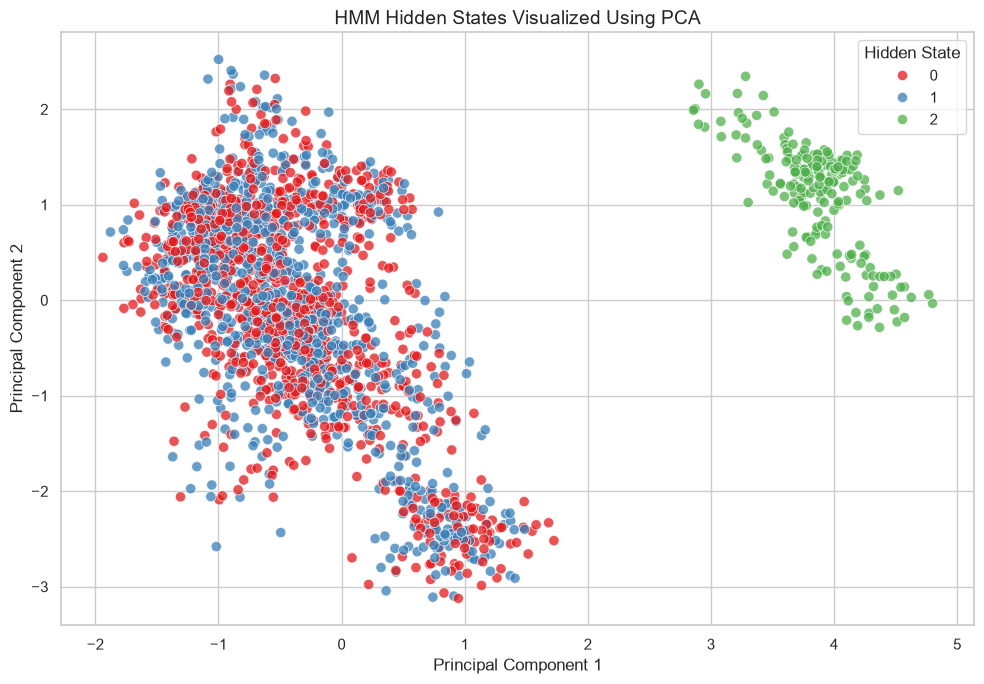

PCA Explained Variance for HMM Visualization:


,Principal Component,Explained Variance (%)
0,PC1,27.59
1,PC2,18.48


Total variance retained: 46.07 %


In [58]:
# ============================================
# HMM HIDDEN STATE VISUALIZATION USING PCA
# ============================================

# Step 1: Reduce the standardized features to 2 dimensions
pca_hmm = PCA(n_components=2)
X_hmm_pca = pca_hmm.fit_transform(X_hmm)

# Step 2: Create a DataFrame for visualization
hmm_pca_df = pd.DataFrame({
    "Principal Component 1": X_hmm_pca[:, 0],
    "Principal Component 2": X_hmm_pca[:, 1],
    "HMM Hidden State": df["HMM_Hidden_State"].to_numpy()
})

# Step 3: Plot the hidden states
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=hmm_pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="HMM Hidden State",
    palette="Set1",
    s=55,
    alpha=0.75
)

plt.title("HMM Hidden States Visualized Using PCA", fontsize=14)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Hidden State")
plt.tight_layout()
plt.show()

# Step 4: Display the explained variance
hmm_pca_variance_df = pd.DataFrame({
    "Principal Component": ["PC1", "PC2"],
    "Explained Variance (%)": (
        pca_hmm.explained_variance_ratio_ * 100
    ).round(2)
})

print("PCA Explained Variance for HMM Visualization:")
display(hmm_pca_variance_df)

print(
    "Total variance retained:",
    round(pca_hmm.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [31]:
# ============================================
# FINAL MODEL COMPARISON
# ============================================

# Step 1: Prepare the clustering results
final_comparison = comparison_df.copy()

# Step 2: Add HMM summary information
hmm_log_likelihood = hmm_model.score(
    X_hmm, lengths=sequence_lengths
)

hmm_states_found = df["HMM_Hidden_State"].nunique()

hmm_summary = pd.DataFrame([{
    "Algorithm": "Gaussian HMM",
    "Number of Clusters": np.nan,
    "Silhouette Score": np.nan,
    "Davies-Bouldin Index": np.nan,
    "Calinski-Harabasz Index": np.nan,
    "Adjusted Rand Index": np.nan
}])

# Step 3: Combine the clustering results and HMM summary
final_comparison = pd.concat(
    [final_comparison, hmm_summary],
    ignore_index=True
)

print("FINAL MODEL COMPARISON")
print("=" * 60)
display(final_comparison.round(4))

# Step 4: Display HMM-specific information separately
hmm_details = pd.DataFrame({
    "Measure": [
        "Number of hidden states specified",
        "Number of hidden states assigned",
        "Log-likelihood",
        "Training converged"
    ],
    "Result": [
        n_hidden_states,
        hmm_states_found,
        round(hmm_log_likelihood, 4),
        hmm_model.monitor_.converged
    ]
})

print("\nHMM MODEL SUMMARY")
display(hmm_details)

FINAL MODEL COMPARISON


,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Adjusted Rand Index
0,K-Means,2.0,0.4168,0.7968,685.7253,0.0185
1,Agglomerative,2.0,0.4168,0.7968,685.7253,0.0185
2,DBSCAN,2.0,0.4168,0.7968,685.7253,0.0185
3,Gaussian HMM,NaN,NaN,NaN,NaN,NaN



HMM MODEL SUMMARY


,Measure,Result
0,Number of hidden states specified,3
1,Number of hidden states assigned,3
2,Log-likelihood,-17251.5092
3,Training converged,True


In [59]:
import numpy as np

# Total log-likelihood
ll = hmm_model.score(X_hmm, lengths=sequence_lengths)

# Number of observations, features and hidden states
n = X_hmm.shape[0]
d = X_hmm.shape[1]
k = hmm_model.n_components

# Number of free model parameters (diagonal covariance)
p = (k - 1) + k * (k - 1) + k * d + k * d

# AIC and BIC
aic = -2 * ll + 2 * p
bic = -2 * ll + p * np.log(n)

# Expected state durations
durations = 1 / (1 - np.diag(hmm_model.transmat_))

print("Log-likelihood per observation:", round(ll / n, 4))
print("AIC:", round(aic, 4))
print("BIC:", round(bic, 4))

print("\nExpected state durations:")
for i, duration in enumerate(durations):
    print(f"State {i}: {duration:.4f} observations")

Log-likelihood per observation: -7.8416
AIC: 34603.0184
BIC: 34887.829

Expected state durations:
State 0: 1.0014 observations
State 1: 1.0135 observations
State 2: inf observations


In [60]:

import numpy as np
from hmmlearn.hmm import GaussianHMM

# Split each artificial sequence into 80% train and 20% test
train_parts = []
test_parts = []
train_lengths = []
test_lengths = []

start = 0

for length in sequence_lengths:
    seq = X_hmm[start:start + length]
    cut = int(0.8 * length)

    train_parts.append(seq[:cut])
    test_parts.append(seq[cut:])

    train_lengths.append(cut)
    test_lengths.append(length - cut)

    start += length

X_train_hmm = np.vstack(train_parts)
X_test_hmm = np.vstack(test_parts)

# Train HMM using training observations only
hmm_train_model = GaussianHMM(
    n_components=3,
    covariance_type="diag",
    n_iter=200,
    random_state=42
)

hmm_train_model.fit(X_train_hmm, lengths=train_lengths)

# Calculate train and test log-likelihood per observation
train_ll = hmm_train_model.score(
    X_train_hmm, lengths=train_lengths
)
test_ll = hmm_train_model.score(
    X_test_hmm, lengths=test_lengths
)

# Calculate AIC and BIC on training data
n = len(X_train_hmm)
d = X_train_hmm.shape[1]
k = hmm_train_model.n_components

p = (k - 1) + k * (k - 1) + 2 * k * d

aic = -2 * train_ll + 2 * p
bic = -2 * train_ll + p * np.log(n)

# Expected state durations
durations = 1 / (1 - np.diag(hmm_train_model.transmat_))

print("TRAINING OBSERVATIONS:", len(X_train_hmm))
print("TEST OBSERVATIONS:", len(X_test_hmm))
print("Model converged:", hmm_train_model.monitor_.converged)
print("Iterations:", hmm_train_model.monitor_.iter)

print("\nTRAIN LOG-LIKELIHOOD PER OBSERVATION:",
      round(train_ll / len(X_train_hmm), 4))

print("TEST LOG-LIKELIHOOD PER OBSERVATION:",
      round(test_ll / len(X_test_hmm), 4))

print("AIC:", round(aic, 4))
print("BIC:", round(bic, 4))

print("\nEXPECTED STATE DURATIONS:")
for i, duration in enumerate(durations):
    print(f"State {i}: {duration:.4f}")


TRAINING OBSERVATIONS: 1760
TEST OBSERVATIONS: 440
Model converged: True
Iterations: 6

TRAIN LOG-LIKELIHOOD PER OBSERVATION: -7.8451
TEST LOG-LIKELIHOOD PER OBSERVATION: -7.8517
AIC: 27714.6766
BIC: 27988.3301

EXPECTED STATE DURATIONS:
State 0: 1.0000
State 1: inf
State 2: inf


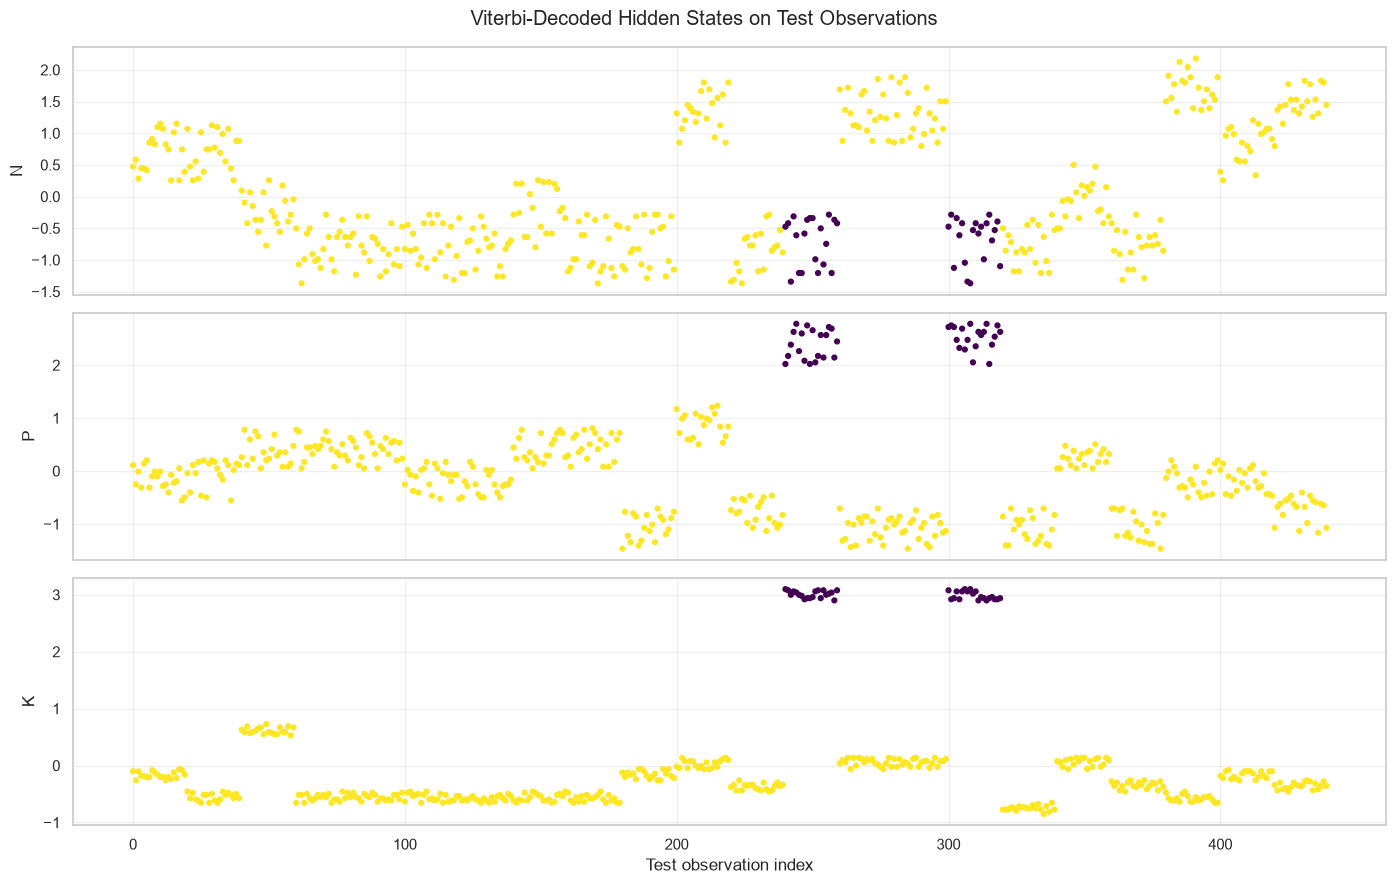

In [61]:

import matplotlib.pyplot as plt
import numpy as np

# Decode hidden states for each test sequence
test_hidden_states = np.concatenate([
    hmm_train_model.predict(
        X_test_hmm[start:start + length]
    )
    for start, length in zip(
        np.cumsum([0] + test_lengths[:-1]),
        test_lengths
    )
])

# Plot test observations coloured by decoded state
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

feature_names = ["N", "P", "K"]

for i, ax in enumerate(axes):
    ax.scatter(
        np.arange(len(X_test_hmm)),
        X_test_hmm[:, i],
        c=test_hidden_states,
        cmap="viridis",
        s=12
    )
    ax.set_ylabel(feature_names[i])
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Test observation index")
fig.suptitle("Viterbi-Decoded Hidden States on Test Observations")
plt.tight_layout()
plt.show()


## 4. Comparative Performance Analysis

The three clustering algorithms—K-Means, Agglomerative Clustering, and DBSCAN—were implemented using standardized agricultural features. Their performance was evaluated using the Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index, and Adjusted Rand Index.

The Silhouette Score measures cluster cohesion and separation, while the Davies–Bouldin and Calinski–Harabasz indices evaluate different aspects of cluster structure. The Adjusted Rand Index compares the discovered clusters with the known crop labels and is used only for external evaluation.

The Gaussian Hidden Markov Model was implemented separately to explore latent states in the agricultural observations. Its state assignments, initial probabilities, transition matrix, and log-likelihood were examined.

### 5. Conclusion

This project explored unsupervised learning and probabilistic state modelling using an agricultural dataset containing soil nutrient values and environmental measurements.

K-Means, Agglomerative Clustering, and DBSCAN demonstrated different approaches to identifying patterns in the data. Their comparative performance can be assessed using internal clustering metrics and agreement with the known crop labels.

The Gaussian HMM demonstrated how hidden states and transition probabilities can be estimated from observed numerical features. However, because the dataset does not contain genuine temporal observations, the inferred transitions cannot be interpreted as actual seasonal changes or crop growth stages.

Overall, the project demonstrates the application, evaluation, and interpretation of clustering algorithms and Hidden Markov Models, while highlighting the importance of dataset suitability and methodological limitations.

In [22]:
# ============================================
# FINAL RESULTS INTERPRETATION
# ============================================

print("FINAL RESULTS INTERPRETATION")
print("=" * 60)

# 1. Best Silhouette Score
valid_silhouette = comparison_df.dropna(
    subset=["Silhouette Score"]
)

if not valid_silhouette.empty:
    best_silhouette_row = valid_silhouette.loc[
        valid_silhouette["Silhouette Score"].idxmax()
    ]

    print("\n1. Best Silhouette Score:")
    print("Algorithm:", best_silhouette_row["Algorithm"])
    print("Score:", round(best_silhouette_row["Silhouette Score"], 4))

# 2. Best Davies-Bouldin Index
valid_db = comparison_df.dropna(
    subset=["Davies-Bouldin Index"]
)

if not valid_db.empty:
    best_db_row = valid_db.loc[
        valid_db["Davies-Bouldin Index"].idxmin()
    ]

    print("\n2. Best Davies-Bouldin Index:")
    print("Algorithm:", best_db_row["Algorithm"])
    print("Score:", round(best_db_row["Davies-Bouldin Index"], 4))

# 3. Best Calinski-Harabasz Index
valid_ch = comparison_df.dropna(
    subset=["Calinski-Harabasz Index"]
)

if not valid_ch.empty:
    best_ch_row = valid_ch.loc[
        valid_ch["Calinski-Harabasz Index"].idxmax()
    ]

    print("\n3. Best Calinski-Harabasz Index:")
    print("Algorithm:", best_ch_row["Algorithm"])
    print("Score:", round(best_ch_row["Calinski-Harabasz Index"], 4))

# 4. Best Adjusted Rand Index
valid_ari = comparison_df.dropna(
    subset=["Adjusted Rand Index"]
)

if not valid_ari.empty:
    best_ari_row = valid_ari.loc[
        valid_ari["Adjusted Rand Index"].idxmax()
    ]

    print("\n4. Best Agreement with Known Crop Labels:")
    print("Algorithm:", best_ari_row["Algorithm"])
    print("ARI:", round(best_ari_row["Adjusted Rand Index"], 4))

# 5. HMM summary
print("\n5. Hidden Markov Model:")
print("Hidden states specified:", n_hidden_states)
print("Hidden states assigned:", df["HMM_Hidden_State"].nunique())
print("Training converged:", hmm_model.monitor_.converged)

print("\nNote: These metrics evaluate different properties.")
print("No single metric alone establishes the universally best model.")
print("HMM transitions are exploratory because the dataset is not temporal.")

FINAL RESULTS INTERPRETATION

1. Best Silhouette Score:
Algorithm: K-Means
Score: 0.4168

2. Best Davies-Bouldin Index:
Algorithm: K-Means
Score: 0.7968

3. Best Calinski-Harabasz Index:
Algorithm: K-Means
Score: 685.7253

4. Best Agreement with Known Crop Labels:
Algorithm: K-Means
ARI: 0.0185

5. Hidden Markov Model:
Hidden states specified: 3
Hidden states assigned: 3
Training converged: True

Note: These metrics evaluate different properties.
No single metric alone establishes the universally best model.
HMM transitions are exploratory because the dataset is not temporal.


## 6. Results and Discussion

### 6.1 Clustering Performance

The three clustering algorithms were evaluated using internal clustering metrics and an external evaluation metric.

K-Means achieved a Silhouette Score of **0.4168**, a Davies–Bouldin Index of **0.7968**, and a Calinski–Harabasz Index of **685.7253**. Among the evaluated algorithms, these results indicate that K-Means provided the strongest performance according to the selected internal clustering metrics.

However, its Adjusted Rand Index (ARI) was **0.0185**, indicating very weak agreement between the discovered clusters and the known crop labels. This demonstrates that good internal cluster structure does not necessarily mean that the clusters correspond to the original crop categories.

### 6.2 Hidden Markov Model Results

A Gaussian Hidden Markov Model with three hidden states was trained on the standardized agricultural features. The model converged and assigned observations to all three states. Its initial-state probabilities, transition matrix, and average agricultural feature values for each inferred state were examined.

The HMM provided an exploratory demonstration of latent-state modelling. However, the dataset does not contain genuine temporal observations. Consequently, the inferred transitions should not be interpreted as actual seasonal changes, crop growth stages, or real-world agricultural transitions.

### 6.3 Overall Discussion

The experiments demonstrate that different clustering algorithms can identify different structures in the same agricultural dataset. Internal evaluation metrics measure the compactness and separation of clusters, whereas the Adjusted Rand Index evaluates their agreement with known crop labels.

The results highlight the importance of selecting suitable evaluation metrics and interpreting model performance in the context of the dataset and the original problem.

## 7. Conclusion

This project applied unsupervised machine learning and probabilistic modelling to an agricultural dataset containing soil nutrient measurements and environmental conditions.

K-Means, Agglomerative Clustering, and DBSCAN were implemented and evaluated using multiple clustering metrics. K-Means achieved the strongest internal evaluation scores among the tested algorithms, although its low Adjusted Rand Index indicated weak agreement with the known crop categories.

A Gaussian Hidden Markov Model was also implemented to explore latent states and transition probabilities. Since the dataset lacks genuine temporal information, the HMM results were treated as exploratory rather than evidence of actual agricultural state transitions.

In conclusion, the project demonstrates the implementation and comparative evaluation of clustering algorithms, the basic operation of a Hidden Markov Model, and the importance of interpreting machine learning results while acknowledging methodological limitations.